# Week 1 — Comparing an Open-Weight Language Model and Image Model on a Common Brief

## 1. Objective
This notebook evaluates how an open-weight language model and an open-weight image generation model respond to the same creative brief. Each output is assessed against the brief for relevance, quality, consistency, creativity and limitations, and the two models are compared on how well each performs its intended task.

## 2. The Common Brief
**TerraFlask** is a fictional reusable insulated water bottle being launched for university students in hot climates.

| Attribute | Specification |
|---|---|
| Material | 90% recycled stainless steel |
| Finish and colour | Matte sage-green body |
| Lid | Natural bamboo lid |
| Performance | Keeps drinks cold for 24 hours |
| Audience | University students in hot-climate cities |
| Sustainability angle | Replaces single-use plastic bottles; works with campus refill stations |
| Tone | Fresh, practical, environmentally conscious |
| Required outputs | Text: a ~120-word product launch description and a tagline. Image: a product hero shot. |

The brief connects to **SDG 12 (Responsible Consumption and Production)**, since it promotes a reusable product that cuts single-use plastic waste.

## 3. Why This Brief
The brief is deliberately specific. Concrete, checkable attributes (colour, materials, a numeric claim, an audience and a setting) let each output be scored against a fixed checklist instead of being judged on general impressions. Some details also test known weaknesses: the "24 hours" figure tests whether the language model keeps facts accurate or invents new ones, and the tagline tests whether the image model can render text, which Stable Diffusion is known to do badly.

### Evaluation checklist (applied to both outputs where relevant)
1. Sage-green colour
2. Bamboo lid
3. Recycled stainless steel
4. 24-hour cold claim
5. Student / hot-climate context
6. Sustainability message
7. Tagline present and legible

## 4. Environment Setup
Experiments run on Google Colab with a T4 GPU (16 GB VRAM). Library versions are printed so the results can be reproduced.

In [2]:
!pip install -q -U diffusers accelerate

import platform
import torch
import transformers
import diffusers

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__, "| CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")
print("transformers:", transformers.__version__, "| diffusers:", diffusers.__version__)

Python: 3.13.16
PyTorch: 2.14.1+cu130 | CUDA available: True
GPU: Tesla T4
transformers: 5.22.1 | diffusers: 0.42.1


## 5. Translating the Brief into Model Prompts
The same brief has to be expressed differently for each model because the two models read text in different ways.

| Aspect | Language model (Qwen2.5-3B-Instruct) | Image model (Stable Diffusion v1.5) |
|---|---|---|
| Input format | Chat messages: a system message setting the role, then a user message with the task | A single comma-separated description, plus a negative prompt |
| What it reads well | Full sentences, explicit instructions, constraints and formatting rules | Visual nouns and adjectives: subject, setting, lighting, style, quality tags |
| What it ignores or handles poorly | Nothing major; it can follow length and format rules | Instructions, numbers and abstract claims ("24 hours", "90% recycled") have no visual form |
| Length limit | Thousands of tokens | 77 tokens (CLIP text encoder); words past the limit are silently dropped |
| Brief attributes used | All of them, including the performance and sustainability claims | Visual ones only: colour, materials, lid, setting, mood |

The text prompt also tells the model to use only the facts provided, so any added claims can be counted as hallucinations. The image prompt puts the most important attributes first, because Stable Diffusion gives earlier tokens more weight.

## 6. Text Generation — Qwen2.5-3B-Instruct
**Model:** `Qwen/Qwen2.5-3B-Instruct` (Qwen Research License: research and evaluation use only; 3.1B parameters, loaded in float16, ~6 GB VRAM).
The 3B variant was chosen over the lab's 7B suggestion because it fits a free T4 in full float16 precision without quantisation and generates several times faster, which leaves room for repeated runs.

Three runs are recorded to separate consistency from creativity:

| Run | Temperature | Seed | Purpose |
|---|---|---|---|
| A | 0.3 | 1 | Focused baseline |
| B | 0.3 | 2 | Same settings, different seed: tests consistency |
| C | 0.9 | 1 | High temperature: tests creativity and factual drift |

All runs use `top_p = 0.9` and `max_new_tokens = 300`.

In [3]:
import time
import json
import os
from transformers import AutoModelForCausalLM, AutoTokenizer

os.makedirs("outputs", exist_ok=True)

MODEL_ID = "Qwen/Qwen2.5-3B-Instruct"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=torch.float16, device_map="cuda")

SYSTEM_PROMPT = (
    "You are a copywriter for a sustainable consumer-goods brand. "
    "You write accurate, concise product copy and never add specifications, "
    "certifications or statistics that are not given in the brief."
)

USER_PROMPT = """Write launch copy for a new product using ONLY the facts below.

Product facts:
- Name: TerraFlask
- Type: reusable insulated water bottle
- Material: 90% recycled stainless steel
- Finish: matte sage-green body
- Lid: natural bamboo
- Performance: keeps drinks cold for 24 hours
- Audience: university students in hot-climate cities
- Sustainability: replaces single-use plastic bottles; works with campus refill stations
- Tone: fresh, practical, environmentally conscious

Output format (follow exactly):
Tagline: <one tagline, maximum 8 words>
Description: <one paragraph of about 120 words>"""

def generate_text(temperature, seed, max_new_tokens=300, top_p=0.9):
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": USER_PROMPT},
    ]
    prompt_text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(prompt_text, return_tensors="pt").to("cuda")

    torch.manual_seed(seed)
    start = time.time()
    output_ids = model.generate(
        **inputs,
        max_new_tokens=max_new_tokens,
        do_sample=True,
        temperature=temperature,
        top_p=top_p,
    )
    elapsed = time.time() - start

    new_tokens = output_ids[0][inputs["input_ids"].shape[1]:]
    text = tokenizer.decode(new_tokens, skip_special_tokens=True).strip()
    return {
        "temperature": temperature,
        "seed": seed,
        "output": text,
        "words": len(text.split()),
        "seconds": round(elapsed, 1),
    }

runs = {
    "A": generate_text(temperature=0.3, seed=1),
    "B": generate_text(temperature=0.3, seed=2),
    "C": generate_text(temperature=0.9, seed=1),
}

for name, r in runs.items():
    print(f"===== Run {name} | temperature={r['temperature']} | seed={r['seed']} | "
          f"{r['words']} words | {r['seconds']} s =====")
    print(r["output"], "\n")

with open("outputs/text_runs.json", "w") as f:
    json.dump(runs, f, indent=2)

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/35.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

===== Run A | temperature=0.3 | seed=1 | 89 words | 7.5 s =====
Tagline: Stay Cool, Go Green

Description: Introducing TerraFlask, the perfect companion for university students in hot-climate cities who care about sustainability. This reusable, 90% recycled stainless steel water bottle features a matte sage-green finish and a natural bamboo lid, ensuring your drink stays cold for up to 24 hours. By choosing TerraFlask, you're making a practical choice for your hydration needs while reducing your reliance on single-use plastic bottles. Perfect for campus life, TerraFlask seamlessly integrates with refill stations, making it an eco-friendly solution for every student's daily routine. 

===== Run B | temperature=0.3 | seed=2 | 104 words | 5.9 s =====
Tagline: Stay Fresh, Go Green

Description: Introducing TerraFlask, the perfect companion for university students in hot-climate cities who want to sip sustainably. Crafted from 90% recycled stainless steel, this durable water bottle keeps yo

### 6.1 Text Output Analysis

| Check | Run A (T=0.3, seed 1) | Run B (T=0.3, seed 2) | Run C (T=0.9, seed 1) |
|---|---|---|---|
| Format followed (Tagline / Description) | Yes | Yes | Yes |
| Tagline ≤ 8 words | Yes (4) | Yes (4) | Yes (4) |
| Length vs ~120-word target | 89 (−26%) | 104 (−13%) | 105 (−13%) |
| All six brief facts included | Yes | Yes | Yes |
| Claims not in the brief | "seamlessly integrates with refill stations" | "durable", "comfortable grip and easy opening", "ideal for long study sessions" | "innovative" |
| Generation time | 7.5 s | 5.9 s | 6.8 s |

**Factual accuracy.** Every run carried over all six facts correctly: 90% recycled steel, sage-green finish, bamboo lid, 24-hour cold retention, the student audience and the refill-station link. No run changed a number. Runs A and B softened the performance claim to "up to 24 hours", which is a hedge the brief did not ask for.

**Hallucination.** Despite the instruction to use only the facts given, every run added something. Run B invented the most: two functional claims about the lid (grip and easy opening) that a customer could hold the brand to. Run A's "seamlessly integrates" overstates a simple compatibility as if it were a technical feature. Run C added only promotional language ("innovative"). The run with the most invented claims was a low-temperature run, so hallucination here depended on the sampling path (seed) more than on temperature.

**Consistency.** Runs A and B share the same structure and almost the same opening sentence ("Introducing TerraFlask, the perfect companion for university students in hot-climate cities who..."), and their taglines differ by one word. At low temperature the model reliably produces the same template.

**Creativity.** Raising temperature to 0.9 changed word choice ("navigating the scorching streets") but not structure or tagline. Run C kept Run A's tagline because both used seed 1. The copy is competent but generic: phrases such as "perfect companion" and "join the movement towards a greener future" are stock marketing language.

**Instruction adherence.** All runs fell short of the ~120-word target. The model treats "about 120 words" loosely, and a stricter instruction (e.g. "between 110 and 130 words") would be needed.

**Relevance to the sustainability theme.** All three runs describe the product as "eco-friendly", a vague claim that is not in the brief and that green-marketing guidance treats as unsubstantiated. This failure mode is examined further in the Week 2 prompt-engineering task.

## 7. Image Generation — Stable Diffusion v1.5
**Model:** `stable-diffusion-v1-5/stable-diffusion-v1-5` (CreativeML OpenRAIL-M licence, 512×512 output, float16). This is the official mirror of the original RunwayML checkpoint, which has been removed from Hugging Face.
The language model is unloaded first to free GPU memory.

**Prompt design.** Only the brief's visual attributes are used, most important first, followed by setting, style and quality tags. A negative prompt suppresses common artefacts and stops the model from drawing a plastic bottle.

**Experiments.** All runs use the default PNDM scheduler.

| Run | Guidance scale | Steps | Seed | Purpose |
|---|---|---|---|---|
| 1 | 7.5 | 25 | 42 | Baseline |
| 2 | 7.5 | 50 | 42 | Effect of more denoising steps |
| 3 | 12.0 | 25 | 42 | Effect of stronger prompt guidance |
| 4 | 12.0 | 50 | 42 | Both increased |
| 5 | 7.5 | 25 | 7 | Same settings as Run 1, new seed: tests consistency |
| 6 | 7.5 | 25 | 42 | Tagline added to the prompt: tests text rendering |

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Prompt length: 45 tokens (CLIP limit 77)


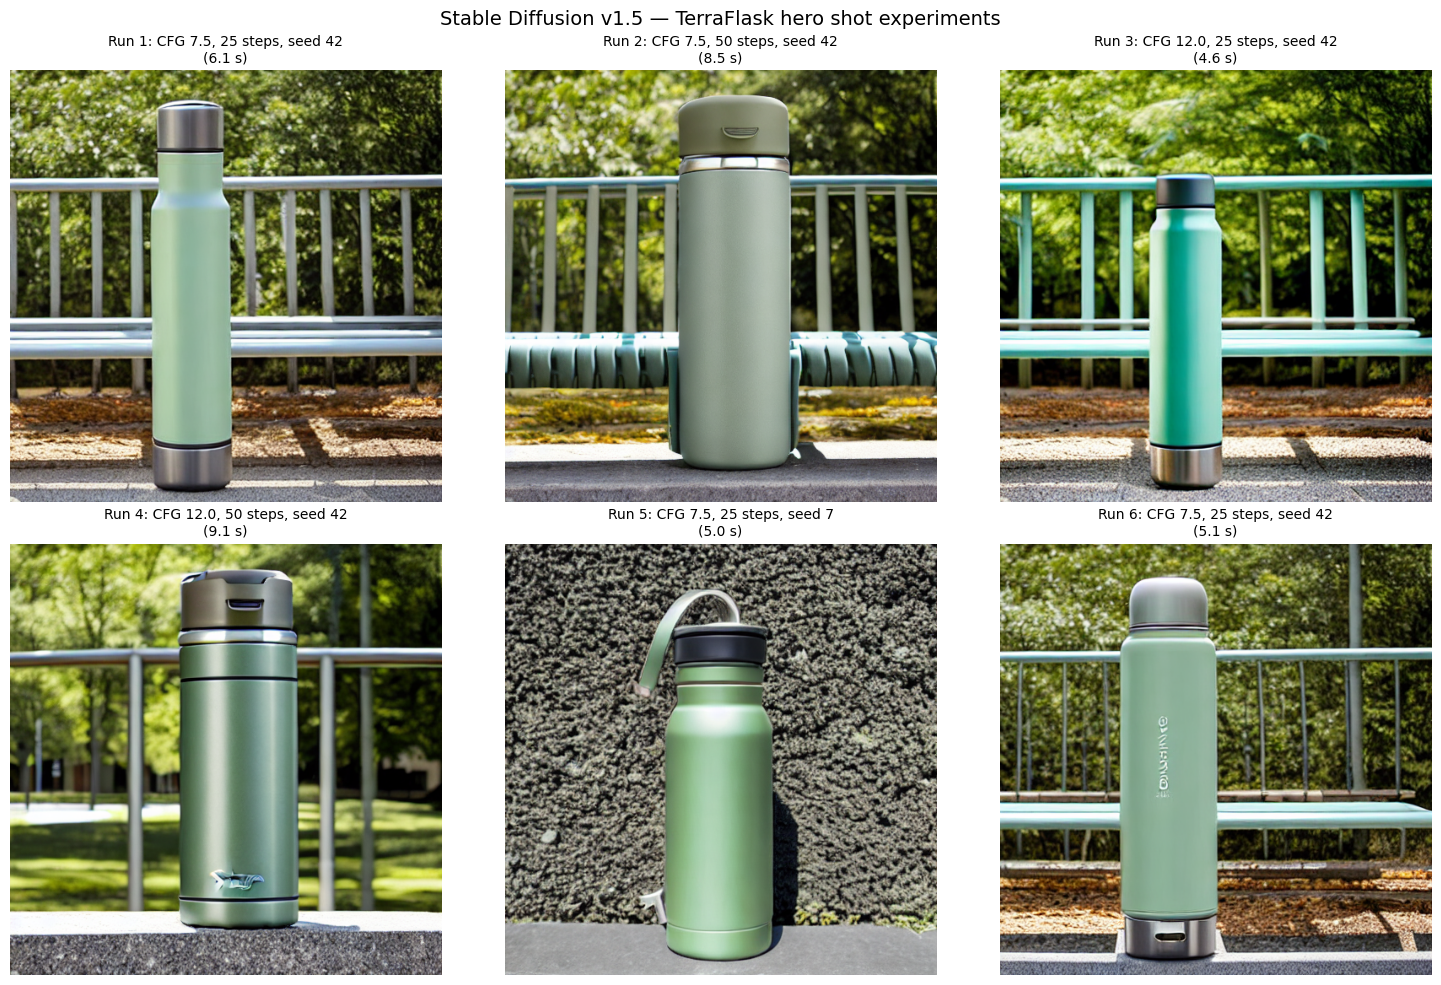

In [4]:
import gc
import matplotlib.pyplot as plt
from diffusers import StableDiffusionPipeline

# Free the language model's GPU memory before loading Stable Diffusion
del model
gc.collect()
torch.cuda.empty_cache()

pipe = StableDiffusionPipeline.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5", torch_dtype=torch.float16
).to("cuda")
pipe.set_progress_bar_config(disable=True)

IMAGE_PROMPT = (
    "product photograph of a matte sage green insulated stainless steel water bottle "
    "with a natural bamboo lid, standing on a sunlit university campus bench, "
    "hot sunny afternoon, clean minimal composition, photorealistic, highly detailed, sharp focus"
)
NEGATIVE_PROMPT = "blurry, low quality, distorted, deformed, watermark, plastic bottle, extra bottles, cluttered"
TAGLINE_PROMPT = IMAGE_PROMPT + ', with the words "Stay Cool, Go Green" printed on the bottle'

n_tokens = len(pipe.tokenizer(IMAGE_PROMPT)["input_ids"])
print(f"Prompt length: {n_tokens} tokens (CLIP limit 77)")

experiments = [
    {"run": 1, "prompt": IMAGE_PROMPT, "guidance": 7.5, "steps": 25, "seed": 42},
    {"run": 2, "prompt": IMAGE_PROMPT, "guidance": 7.5, "steps": 50, "seed": 42},
    {"run": 3, "prompt": IMAGE_PROMPT, "guidance": 12.0, "steps": 25, "seed": 42},
    {"run": 4, "prompt": IMAGE_PROMPT, "guidance": 12.0, "steps": 50, "seed": 42},
    {"run": 5, "prompt": IMAGE_PROMPT, "guidance": 7.5, "steps": 25, "seed": 7},
    {"run": 6, "prompt": TAGLINE_PROMPT, "guidance": 7.5, "steps": 25, "seed": 42},
]

for exp in experiments:
    generator = torch.Generator("cuda").manual_seed(exp["seed"])
    start = time.time()
    image = pipe(
        exp["prompt"],
        negative_prompt=NEGATIVE_PROMPT,
        guidance_scale=exp["guidance"],
        num_inference_steps=exp["steps"],
        generator=generator,
    ).images[0]
    exp["seconds"] = round(time.time() - start, 1)
    exp["file"] = f"outputs/image_run{exp['run']}.png"
    image.save(exp["file"])
    exp["image"] = image

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, exp in zip(axes.flat, experiments):
    ax.imshow(exp["image"])
    ax.set_title(f"Run {exp['run']}: CFG {exp['guidance']}, {exp['steps']} steps, "
                 f"seed {exp['seed']}\n({exp['seconds']} s)", fontsize=10)
    ax.axis("off")
plt.suptitle("Stable Diffusion v1.5 — TerraFlask hero shot experiments", fontsize=14)
plt.tight_layout()
plt.savefig("outputs/image_grid.png", dpi=120)
plt.show()

with open("outputs/image_runs.json", "w") as f:
    json.dump([{k: v for k, v in e.items() if k != "image"} for e in experiments], f, indent=2)

### 7.1 Image Output Analysis

| Run | Settings | What the image shows | Issues |
|---|---|---|---|
| 1 | CFG 7.5, 25 steps, seed 42 | Slim sage-green bottle in front of a park railing, trees behind, strong sunlight | Steel cap instead of bamboo lid; railing rather than a bench |
| 2 | CFG 7.5, 50 steps, seed 42 | Wider tumbler shape with an olive-green lid, in front of a teal bench | Shape and lid redesigned from Run 1 despite the same seed; lid is green, not bamboo |
| 3 | CFG 12, 25 steps, seed 42 | Same layout as Run 1, but saturated teal-mint body and dark cap | Colour drifts away from sage; looks over-processed |
| 4 | CFG 12, 50 steps, seed 42 | Darker metallic-green bottle on a stone ledge, park behind | Garbled emblem near the base; no bamboo lid |
| 5 | CFG 7.5, 25 steps, seed 7 | Sage bottle with a carry loop and black cap against a dark textured wall | Campus and sunlight setting lost entirely; small spout-like artefact at the base |
| 6 | Run 1 + tagline in prompt | Sage bottle with vertical lettering | Text is illegible; letters are invented shapes, not "Stay Cool, Go Green" |

**Prompt faithfulness.** Colour was the one attribute reliably reproduced: five of six images are recognisably sage green. The bamboo lid, the second word in the prompt's product description, appeared in **none** of the six images. Lids came out as steel, black or green, and in Runs 2 and 4 the green "leaked" from the body onto the lid. This is the attribute-binding weakness of Stable Diffusion v1.5: the CLIP text encoder captures which concepts are present but not which object each adjective belongs to.

**Effect of settings.**
- *Guidance scale* had the most visible effect on colour. At CFG 12 (Run 3) the sage became a saturated teal, so stronger guidance exaggerated the colour instead of making it more accurate.
- *Inference steps* changed the composition more than the detail. With the same seed, 25 steps (Run 1) and 50 steps (Run 2) produced different bottle shapes and lids, because the scheduler takes a different denoising path. More steps did not mean a better match to the brief.
- *Seed* had the largest effect of all. Run 5 used the same settings as Run 1 with a different seed and lost the setting completely.

**Consistency.** Low. A fixed seed reproduces an image exactly, but any change in seed or step count produces a different product design. For a brand that needs the same product in every image, this model would not be reliable on its own.

**Text rendering.** Run 6 confirms the known limitation: Stable Diffusion v1.5 cannot spell. It produced vertical pseudo-letters that look like text but read as nothing.

**Contextual bias.** Despite "hot sunny afternoon" and "university campus", every outdoor image shows a temperate, green, European-style park: lush trees, grass, metal railings. Nothing suggests a hot-climate city such as Riyadh or Kuala Lumpur, or a university. This matches the documented training bias of Stable Diffusion towards Western imagery, and it matters for a brand targeting students in hot climates.

**Visual quality.** Photorealism is good at 512×512: clean lighting, believable shadows, a sharp product and a pleasant background blur. The artefacts are minor (an emblem in Run 4, a spout in Run 5) and appear on the product rather than in the scene.

## 8. Evaluation Against the Brief
The best output from each model was scored against the seven-point checklist from Section 3: Run C for text, which added the fewest invented claims, and Run 1 for the image, which came closest to the brief.

| Checklist item | Qwen2.5-3B (Run C) | Stable Diffusion (Run 1) |
|---|---|---|
| 1. Sage-green colour | Met | Met |
| 2. Bamboo lid | Met | **Missed** (steel cap) |
| 3. Recycled stainless steel | Met | Partly (steel trim visible; "recycled" cannot be shown visually) |
| 4. 24-hour cold claim | Met | Not applicable (no visual form) |
| 5. Student / hot-climate context | Met | **Missed** (temperate park, no campus cues) |
| 6. Sustainability message | Met (but uses the vague term "eco-friendly") | Missed |
| 7. Tagline present and legible | Met | **Missed** (Run 6 illegible) |
| **Applicable items met** | **7 / 7** | **1 / 5 fully, 1 / 5 partly** |

Scores on the lab's 1–5 rubric:

| Dimension | Qwen2.5-3B | Stable Diffusion v1.5 |
|---|---|---|
| Quality | 4 — fluent and polished, some stock phrasing | 4 — photorealistic with minor artefacts |
| Prompt adherence | 4 — all facts and format, but short and with small additions | 2 — colour right, lid, setting and text wrong |
| Coherence / consistency | 5 — same structure across seeds and temperatures | 2 — design changes with every seed or step change |
| Usefulness | 4 — usable after a quick fact-check | 2 — usable as a mood image, not as a product shot |
| **Total** | **17 / 20** | **10 / 20** |

## 9. Comparison and Conclusion

| Criterion | Qwen2.5-3B-Instruct | Stable Diffusion v1.5 |
|---|---|---|
| Relevance to brief | Every fact carried over | General idea right, specific attributes lost |
| Quality | Professional, slightly generic | High visual quality at 512×512 |
| Consistency | High: same template across runs | Low: sensitive to seed and step count |
| Creativity | Limited; formulaic marketing language | Higher; each run explored a new design |
| Main limitations | Invents small claims despite instructions; ignores word targets; uses vague green language | Cannot bind attributes to objects, cannot render text, defaults to Western scenery, cannot show non-visual claims |

**Which model performs better at its task?** The two models do different jobs, so the fair question is how well each completes its own part of the brief. **Qwen2.5-3B performs its task better.** It met every applicable checklist item. Its failures (small invented claims, short length) are easy for a human editor to spot and fix. Stable Diffusion produced attractive images, but it missed the product's most distinctive feature in all six attempts, could not render the tagline, and could not place the product in the intended context. A marketing team could publish the text after a quick fact-check. They could not publish any of the images as a TerraFlask product shot.

**Why the gap exists.** A language model can copy facts straight from its prompt into its output, so following a specification is close to its core skill. A diffusion model has to translate words into visual concepts through a 77-token CLIP encoder. That encoder knows a bamboo lid and a green bottle are both present, but not reliably which object should be bamboo. Exact specifications, numbers and text all fall outside what it does well.

**Practical recommendation.** Use the language model for copy, with human review for added claims and vague terms such as "eco-friendly". Use the image model for early mood boards rather than final product images. Accurate product visuals would need image conditioning (img2img, inpainting or ControlNet with a photo of the real bottle), and the tagline should be added in design software afterwards. Both outputs need a human check before publication, for factual accuracy in the text and for contextual bias in the images.